# **Lab Report: Leap Frog Method Assignment**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

# **Leapfrog Method: Electron Plasma Oscillation**

The leapfrog method solves equations of motion step by step. This method is used to get small errors at larger time steps.\
Consider a system whose motion is described by Newton's second law

$$\frac{d^2x}{dt^2} = a(x)$$

$a(x)$ is the acceleration, which depends on position.\
This is a second order differentila function so we can make this into two first order derivatives.\
$$\frac{dx}{dt} = v$$\
$$\frac{dv}{dt} = a(x)$$\
So, we can use leap frog method to solve this:\
In this method, Acceleration and position are in full steps, and Velocity is at half steps.\
$$v_{n+1/2} = v_{n-1/2} + \Delta t \cdot a(x_n)$$\
$$x_{n+1} = x_n + \Delta t \cdot v_{n + 1/2}$$\
Position and Acceleration jumps to full steps where velocity jumps at half steps, Thats why the name leap frog method.

> [**REF**](https://www.youtube.com/watch?v=pVudb6-_FaM)

## **Problem Statement:**

*   **Electron plasma oscillation**: An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field
proportional to its displacement, and oscillates at the plasma frequency ωp. In normalized units
(ωp = 1), the motion is
$$\frac{dx}{dt} = v, \quad \frac{dv}{dt} = -\omega_p^2x, \quad \omega_p=1$$

$$x(0) = 0.5, \quad v(0) = 0, \quad 0 ≤t≤20$$


*   **Exact solution:**:

$$x(t) = 0.5cost,\quad v(t) = - 0.5sint$$


In [2]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

## **Task 1: Leapfrog function**

In [4]:
wp = 1   # plasma frequency

def leapfrog(x, v, h):
    v = v - h * wp**2 * x   
    x = x + h * v          
    return x, v

## **Task 2: Initialize the half step**

$$v_{-1/2} = v_0 - \frac{h}{2}a(x_0), \quad a(x) = -\omega_p^2 x$$

In [40]:
x_0 = 0.5
v_0 = 0
h = 0.1

v_half = v_0 - h/2 * (-wp**2 * x_0)
print("v(-1/2) =", v_half)

v(-1/2) = 0.025


## **Task 3: Check the implementation ($h = 0.1$, $t = 20$)**

This function runs the leapfrog loop. After step $n$, $x$ is at time $nh$, but $v$ is at time $nh - h/2$.

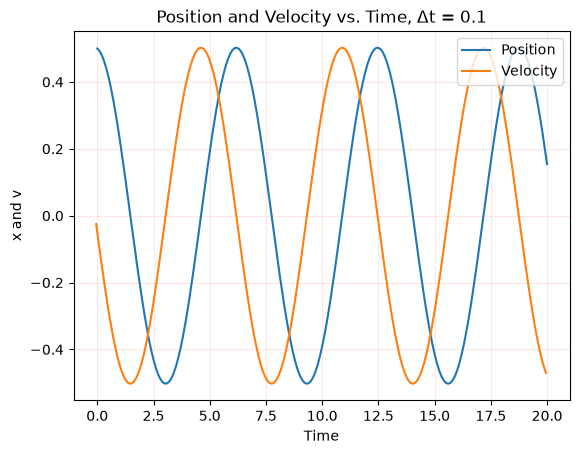

In [41]:
t = (0, 20)
v_i = v_0 - h/2 * wp* x_0

timestep = np.arange(t[0], t[1] + h/2, h)
n = len(timestep)

x, v = np.zeros_like(timestep), np.zeros_like(timestep)
x[0], v[0] = x_0, v_i
for i in range(1, n):
    x[i], v[i] = leapfrog(x[i-1], v[i-1], h)

plt.plot(timestep, x, label='Position')
plt.plot(timestep - h/2, v, label='Velocity')
plt.grid(True, color='r', alpha = 0.1)
plt.legend(loc='upper right')
plt.xlabel('Time')
plt.ylabel('x and v')
plt.title('Position and Velocity vs. Time, Δt = 0.1')
plt.show()

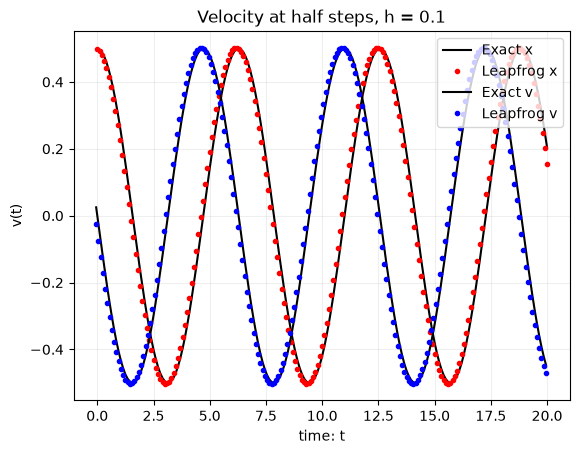

In [42]:
plt.plot(timestep, 0.5*np.cos(timestep), 'k', label='Exact x')
plt.plot(timestep, x, 'r.', label='Leapfrog x')
plt.xlabel('time: t')
plt.ylabel('x(t)')
plt.title('Position at whole steps, h = 0.1')
plt.plot(timestep - h/2, -0.5*np.sin(timestep - h/2), 'k', label='Exact v')
plt.plot(timestep - h/2, v, 'b.', label='Leapfrog v')
plt.xlabel('time: t')
plt.ylabel('v(t)')
plt.title('Velocity at half steps, h = 0.1')
plt.grid(True, alpha=0.2)
plt.legend(loc='upper right')
plt.show()

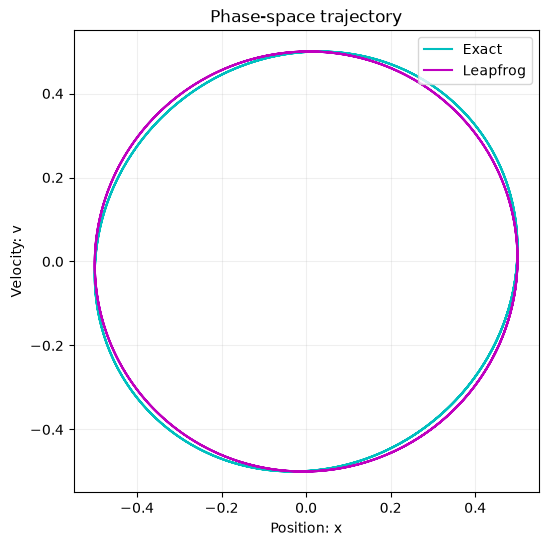

In [80]:
plt.figure(figsize=(6, 6))
plt.plot(x, -0.5*np.sin(timestep - h/2), 'c', label='Exact')
plt.plot(x, v, 'm', label='Leapfrog')
plt.xlabel('Position: x')
plt.ylabel('Velocity: v')
plt.title('Phase-space trajectory')
plt.grid(True, alpha=0.2)
plt.legend(loc='upper right')
plt.show()

## **Task 4: Convergence**

Maximum error in $x$ for each $h$, and the observed order $p = \log_2\left(e(h)/e(h/2)\right)$.

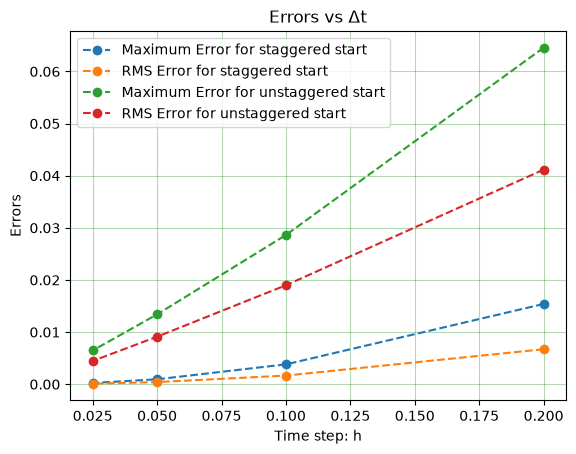

 h     |  error(stag)|  p     |  error(unstag)|    p     |
0.2    | 1.53962e-02 |        |   6.45571e-02 |
0.1    | 3.81528e-03 |   2.01 |   2.86283e-02 |     1.17 |
0.05   | 9.51695e-04 |   2.00 |   1.34017e-02 |     1.10 |
0.025  | 2.37791e-04 |   2.00 |   6.47540e-03 |     1.05 |


In [81]:
hl = [0.2, 0.1, 0.05, 0.025]
max_error_stag = np.zeros_like(hl)
rms_error_stag = np.zeros_like(hl)
max_error_unstag = np.zeros_like(hl)
rms_error_unstag = np.zeros_like(hl)
# staggered start:
for i in range(len(hl)):
    v_i = v_0 + hl[i]/2* wp*x_0
    timestep = np.arange(t[0], t[1] + hl[i]/2, hl[i])
    n = len(timestep)
    x_ori = 0.5*np.cos(timestep)
    v_ori = -0.5*np.sin(timestep - hl[i]/2)
    x, v = np.zeros_like(timestep), np.zeros_like(timestep)
    x[0], v[0] = x_0, v_i
    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], hl[i])
    max_error_stag[i] = np.max(np.abs(x_ori - x))
    rms_error_stag[i] = np.sqrt(np.mean((x_ori - x)**2))
# unstaggered start:    
for i in range(len(hl)):
    v_i = v_0 
    timestep = np.arange(t[0], t[1] + hl[i]/2, hl[i])
    n = len(timestep)
    x_ori = 0.5*np.cos(timestep)
    v_ori = -0.5*np.sin(timestep - hl[i]/2)
    x, v = np.zeros_like(timestep), np.zeros_like(timestep)
    x[0], v[0] = x_0, v_i
    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], hl[i])
    max_error_unstag[i] = np.max(np.abs(x_ori - x))
    rms_error_unstag[i] = np.sqrt(np.mean((x_ori - x)**2))
# plotting error vs delta t
plt.plot(hl, max_error_stag, "o--", label="Maximum Error for staggered start")
plt.plot(hl, rms_error_stag, "o--", label="RMS Error for staggered start")
plt.plot(hl, max_error_unstag, "o--", label="Maximum Error for unstaggered start")
plt.plot(hl, rms_error_unstag, "o--", label="RMS Error for unstaggered start")
plt.xlabel('Time step: h')
plt.ylabel('Errors')
plt.grid(True, color='g', alpha=0.3)
plt.title("Errors vs Δt")
plt.legend()
plt.show()
# for tabulation and observed error
print(" h     |  error(stag)|  p     |  error(unstag)|    p     |")
for i in range(len(hl)):
    if i == 0:
        print(f"{hl[i]:<6} | {max_error_stag[i]:.5e} |        |   {max_error_unstag[i]:.5e} |")
    else:
        p1 = np.log2(max_error_stag[i-1] / max_error_stag[i])
        p2 = np.log2(max_error_unstag[i-1] / max_error_unstag[i])
        print(f"{hl[i]:<6} | {max_error_stag[i]:.5e} |   {p1:.2f} |   {max_error_unstag[i]:.5e} |     {p2:.2f} |")

Here, From the table we can observe that for staggered case the oder p goes to 2 and for unstaggered case it is going to 1. Because setting $v_{-1/2} = v_0$ puts the velocity at the wrong time. Its error is $\frac{h}{2}a(x_0)$, which is proportional to $h$. The method itself is still second order, but this first-order error at the start is carried through the whole run and dominates the error.

## **Task 5: Order of the method**

Start with the two leapfrog equations:

$$v_{n+1/2} = v_{n-1/2} + h \cdot a(x_n) \quad \text{--- (1)}$$
$$x_{n+1} = x_n + h \cdot v_{n+1/2} \quad \text{--- (2)}$$

From (2):
$$v_{n+1/2} = \frac{x_{n+1} - x_n}{h} \quad \text{--- (3)}, \qquad v_{n-1/2} = \frac{x_n - x_{n-1}}{h} \quad \text{--- (4)}$$

Put (3) and (4) into (1) with $a(x_n) = -\omega_p^2 x_n$:
$$\frac{x_{n+1} - x_n}{h} = \frac{x_n - x_{n-1}}{h} - h\omega_p^2 x_n$$

Multiply by $h$ and rearrange:
$$\mathbf{x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n}$$

**Order:** Using Taylor series, $x(t \pm h) = x \pm h x' + \frac{h^2}{2}x'' \pm \frac{h^3}{6}x''' + \frac{h^4}{24}x'''' + \dots$

Adding them: $\dfrac{x_{n+1} - 2x_n + x_{n-1}}{h^2} = x'' + \dfrac{h^2}{12}x'''' + \dots$

The error term is $h^2$, so the method is second order, which we can see from the table above the order goes to 2.

## **Task 6: Stability limit**

Rearrange the central-difference formula:
$$x_{n+1} - (2 - \omega_p^2 h^2)x_n + x_{n-1} = 0$$\
Assume $x_n = g^n$ and divide by $g^{n-1}$:
$$g^2 - (2 - \omega_p^2 h^2)g + 1 = 0$$\
The product of two roots  $g_1 g_2 = 1$.\
If $\omega_p h < 2$: the roots are complex with $|g| = 1$, so the solution stays bounded. **Stable.**\
If $\omega_p h > 2$: the roots are real, and since they multiply to 1, one has $|g| > 1$. The solution grows every step. **Unstable.**\
So the stability condition is $\mathbf{\omega_p h < 2}$.

In [82]:
for wh in [1.9, 1.99, 2.01, 2.1]:
    g = np.roots([1, -(2 - wh**2), 1])
    print("wp*h =", wh, "  |g| =", np.abs(g))

wp*h = 1.9   |g| = [1. 1.]
wp*h = 1.99   |g| = [1. 1.]
wp*h = 2.01   |g| = [1.22130109 0.81879891]
wp*h = 2.1   |g| = [1.87732804 0.53267196]
